# Stochastic Simulation of Monsoon Dry-Spell Risk in Colombo and Hambantota Using Markov Chains
Stochastic Simulation of Monsoon Dry-Spell Risk in Colombo and Hambantota Using Markov Chains
This notebook estimates long dry-spell risk during Sri Lanka’s Southwest (SWM) and Northeast (NEM) monsoons using daily precipitation from the Open-Meteo Historical Weather API (ERA5 reanalysis). Wet and dry days are modelled with first-order and second-order Markov chains, while rainfall amounts on wet days are represented with a threshold-truncated Gamma distribution. Historical observations and repeated simulations are compared to estimate risk and simulation uncertainty. The study period is 1 December 1990 to 30 September 2020, with a wet-day threshold of 1 mm/day. These estimates describe the fitted model and are not forecasts.
## 1. Problem and Research Questions

Long dry spells can affect crop planning and water availability. This project compares dry-spell risk between Colombo and Hambantota across the two monsoon seasons. It asks:
1. What is the simulated probability of at least one dry spell lasting seven or more consecutive days within each season and location?
2. How do first-order and second-order Markov models differ in the estimated risk and average longest dry spell?

The results are risk estimates, not weather forecasts.

## 2. Model, assumptions and equations

Daily precipitation is classified as wet when it is at least 1 mm and dry otherwise. Southwest monsoon is May–September; Northeast monsoon is December–February. December is assigned to the following January–February season-year. Inter-monsoon months are excluded.

Let $X_t\in\{0,1\}$, where 0 is dry and 1 is wet. The first-order Markov assumption is:

$$P(X_{t+1}=j\mid X_t=i,X_{t-1},\ldots)=P_{ij}.$$

Transition probabilities are estimated from adjacent-day counts:

$$P_{ij}=\frac{N_{ij}}{\sum_{k=0}^{1}N_{ik}},\quad i,j\in\{0,1\}.$$

The stationary distribution satisfies $\boldsymbol{\pi}P=\boldsymbol{\pi}$ and $\pi_0+\pi_1=1$. The expected dry spell length for the first-order chain is $E[L_D]=1/(1-P_{00})$, when $P_{00}<1$.

The second-order chain uses the pair $(X_{t-1},X_t)$, coded DD, DW, WD or WW, to model tomorrow’s state from the previous two days.

For wet-day rainfall $R$, a Gamma distribution is fitted conditional on exceeding $u=1$ mm. Its truncated density is:

$$f_T(r;\theta)=\frac{f_\Gamma(r;\theta)}{1-F_\Gamma(u;\theta)},\quad r\ge u.$$

Parameters are estimated by maximum likelihood using the truncated likelihood. Gamma and lognormal fits are compared with AIC; Gamma is used to generate wet-day amounts.

For each simulated season, metrics include whether any dry spell reaches seven days, longest dry spell, mean dry-spell length and wet-day fraction. Estimates are summarized over independent seeds with 95% Student-t confidence intervals. Historical proportions use Wilson intervals.

### Module-topic connections

| Model element | Module topic |
|---|---|
| Transition probabilities and stationary distribution | Discrete-time stochastic processes and Markov chains |
| Second-order state representation | Markov modelling and state-space construction |
| Truncated likelihood and rainfall fitting | Probability distributions and parameter estimation |
| Monte Carlo seasons and independent seeds | Monte Carlo simulation and sampling variability |
| Confidence intervals and model comparison | Statistical inference and uncertainty quantification |


## 3. Implementation

Run the notebook cells in order. The code installs and imports dependencies, specifies the study dates, coordinates, rainfall threshold and seasonal definitions, downloads daily precipitation, validates the data, fits rainfall distributions and Markov transition models, and simulates seasonal outcomes.



In [1]:
!pip -q install requests pandas numpy matplotlib scipy

In [2]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy import stats
from scipy.optimize import minimize

SEED = 42

print("Libraries imported successfully.")
print("Random seed:", SEED)

Libraries imported successfully.
Random seed: 42


In [3]:
# Historical data period
START_DATE = "1990-12-01"
END_DATE = "2020-09-30"

# Daily rainfall classification threshold
WET_DAY_THRESHOLD = 1.0  # mm/day

# Location coordinates
LOCATIONS = {
    "Colombo": {
        "latitude": 6.9271,
        "longitude": 79.8612
    },
    "Hambantota": {
        "latitude": 6.1241,
        "longitude": 81.1185
    }
}

# Open-Meteo historical weather API
API_URL = "https://archive-api.open-meteo.com/v1/archive"

print("Project configuration completed.")

Project configuration completed.


In [4]:
def download_rainfall(location_name, coordinates):

    params = {
        "latitude": coordinates["latitude"],
        "longitude": coordinates["longitude"],
        "start_date": START_DATE,
        "end_date": END_DATE,
        "daily": "precipitation_sum",
        "timezone": "Asia/Colombo",
        "precipitation_unit": "mm",
        "models": "era5"
    }

    response = requests.get(
        API_URL,
        params=params,
        timeout=120
    )

    response.raise_for_status()

    data = response.json()

    if data.get("error"):
        raise ValueError(data.get("reason"))

    daily = data["daily"]

    df = pd.DataFrame({
        "date": pd.to_datetime(daily["time"]),
        "rainfall_mm": daily["precipitation_sum"]
    })

    df["location"] = location_name

    print(f"\n{location_name}")
    print("Returned grid latitude:", data["latitude"])
    print("Returned grid longitude:", data["longitude"])
    print("Grid elevation:", data.get("elevation"))
    print("Timezone:", data.get("timezone"))
    print("Number of daily records:", len(df))

    return df


# Download data for both locations
rainfall_data = {}

for location, coordinates in LOCATIONS.items():

    rainfall_data[location] = download_rainfall(
        location,
        coordinates
    )

print("\nHistorical rainfall downloads completed.")


Colombo
Returned grid latitude: 7.0
Returned grid longitude: 80.0
Grid elevation: 9.0
Timezone: Asia/Colombo
Number of daily records: 10897

Hambantota
Returned grid latitude: 6.25
Returned grid longitude: 81.0
Grid elevation: 8.0
Timezone: Asia/Colombo
Number of daily records: 10897

Historical rainfall downloads completed.


In [5]:
for location, df in rainfall_data.items():

    print("\n" + "=" * 45)
    print(location)
    print("=" * 45)

    print("\nFirst five observations:")
    display(df.head())

    print("\nLast five observations:")
    display(df.tail())

    print("\nMissing values:")
    print(df.isna().sum())

    print("\nData information:")
    print(df.info())

    print("\nRainfall statistics:")
    display(df["rainfall_mm"].describe())

    # Basic validation
    assert df["date"].is_monotonic_increasing
    assert not df["date"].duplicated().any()

    valid_rainfall = df["rainfall_mm"].dropna()

    assert (valid_rainfall >= 0).all()

    print("\nBasic checks passed.")


Colombo

First five observations:


,date,rainfall_mm,location
0,1990-12-01,4.7,Colombo
1,1990-12-02,10.6,Colombo
2,1990-12-03,11.3,Colombo
3,1990-12-04,8.9,Colombo
4,1990-12-05,0.0,Colombo



Last five observations:


,date,rainfall_mm,location
10892,2020-09-26,8.8,Colombo
10893,2020-09-27,1.5,Colombo
10894,2020-09-28,9.8,Colombo
10895,2020-09-29,16.6,Colombo
10896,2020-09-30,8.8,Colombo



Missing values:
date           0
rainfall_mm    0
location       0
dtype: int64

Data information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10897 entries, 0 to 10896
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   date         10897 non-null  datetime64[ns]
 1   rainfall_mm  10897 non-null  float64       
 2   location     10897 non-null  object        
dtypes: datetime64[ns](1), float64(1), object(1)
memory usage: 255.5+ KB
None

Rainfall statistics:


,rainfall_mm
count,10897.000000
mean,6.970891
std,10.108799
min,0.000000
25%,0.800000
50%,3.600000
75%,9.300000
max,231.400000


... (3 outputs left out)

,date,rainfall_mm,location
10892,2020-09-26,1.2,Hambantota
10893,2020-09-27,0.4,Hambantota
10894,2020-09-28,1.0,Hambantota
10895,2020-09-29,1.1,Hambantota
10896,2020-09-30,4.7,Hambantota



Missing values:
date           0
rainfall_mm    0
location       0
dtype: int64

Data information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10897 entries, 0 to 10896
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   date         10897 non-null  datetime64[ns]
 1   rainfall_mm  10897 non-null  float64       
 2   location     10897 non-null  object        
dtypes: datetime64[ns](1), float64(1), object(1)
memory usage: 255.5+ KB
None

Rainfall statistics:


,rainfall_mm
count,10897.000000
mean,2.660916
std,6.336830
min,0.000000
25%,0.000000
50%,0.500000
75%,2.500000
max,160.000000



Basic checks passed.


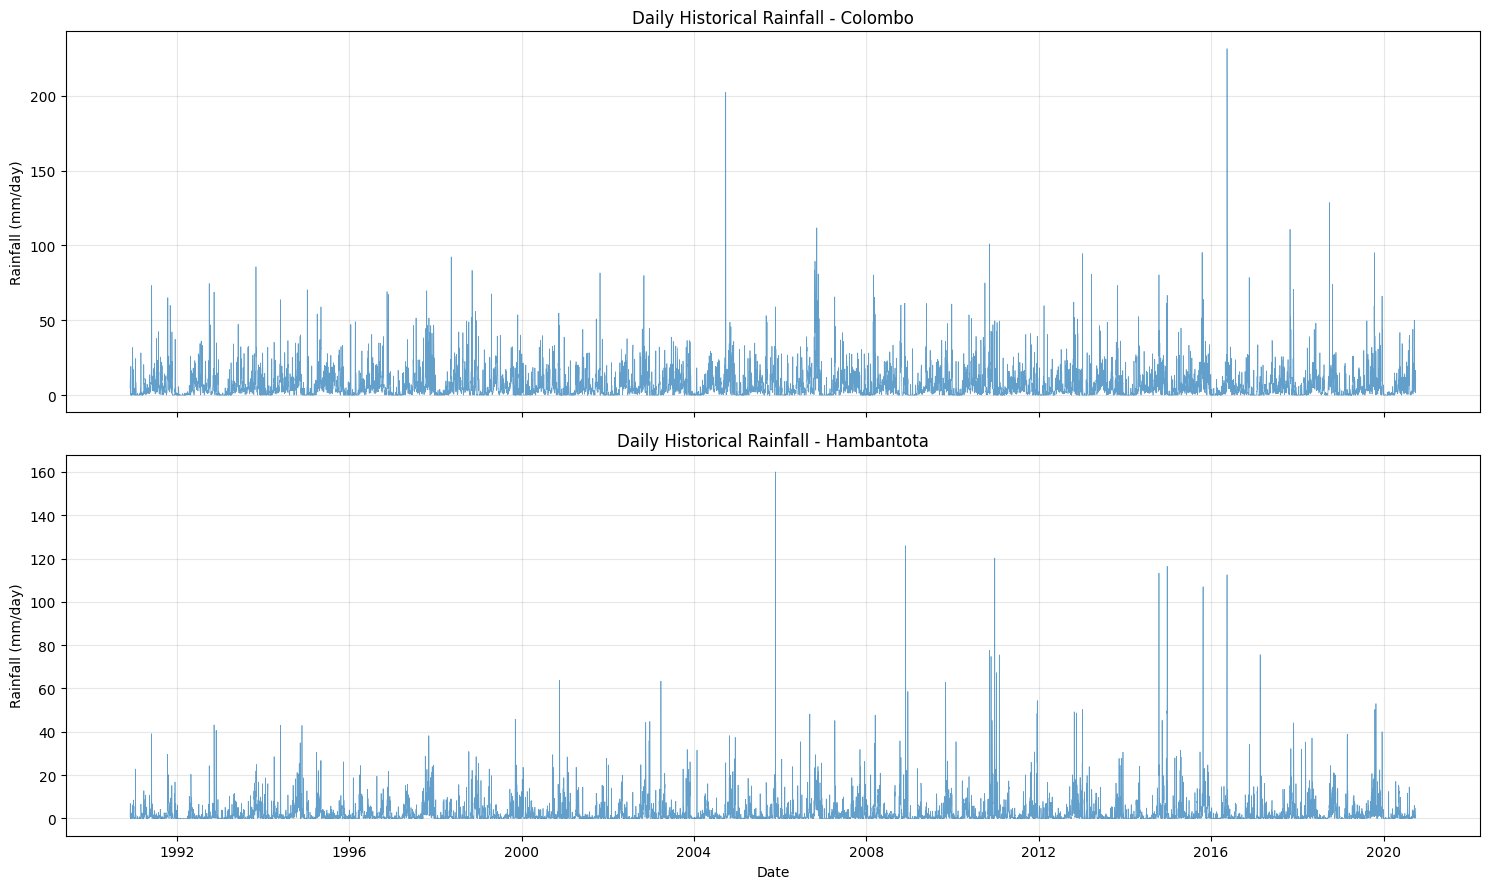

In [6]:
fig, axes = plt.subplots(
    2, 1,
    figsize=(15, 9),
    sharex=True
)

for ax, location in zip(axes, LOCATIONS.keys()):

    df = rainfall_data[location]

    ax.plot(
        df["date"],
        df["rainfall_mm"],
        linewidth=0.5,
        alpha=0.7
    )

    ax.set_title(f"Daily Historical Rainfall - {location}")
    ax.set_ylabel("Rainfall (mm/day)")
    ax.grid(alpha=0.3)

axes[-1].set_xlabel("Date")

plt.tight_layout()
plt.show()

## 3. Seasons and wet-day rainfall

In [7]:
weather = {}

for loc, df in rainfall_data.items():
    d = df.copy()
    d["month"] = d["date"].dt.month
    d["season"] = np.select(
        [d["month"].between(5, 9), d["month"].isin([12, 1, 2])],
        ["SWM", "NEM"],
        default="inter"
    )
    # december belongs to the northeast monsoon of the following year
    d["season_year"] = np.where(d["month"] == 12, d["date"].dt.year + 1, d["date"].dt.year)
    d["wet"] = (d["rainfall_mm"] >= WET_DAY_THRESHOLD).astype(int)
    weather[loc] = d

# one array per monsoon season (year), so transitions never cross a season boundary
wet_blocks, rain_blocks, wet_amounts = {}, {}, {}

for loc, d in weather.items():
    for season in ["SWM", "NEM"]:
        sub = d[d["season"] == season].sort_values("date")
        groups = [g for _, g in sub.groupby("season_year")]
        key = (loc, season)
        wet_blocks[key] = [g["wet"].to_numpy() for g in groups]
        rain_blocks[key] = [g["rainfall_mm"].to_numpy() for g in groups]
        wet_amounts[key] = np.concatenate(
            [r[w == 1] for r, w in zip(rain_blocks[key], wet_blocks[key])]
        )

SEASON_LEN = {
    season: int(round(np.mean([len(w) for key, blocks in wet_blocks.items()
                               if key[1] == season for w in blocks])))
    for season in ["SWM", "NEM"]
}

for key, blocks in wet_blocks.items():
    lengths = [len(w) for w in blocks]
    print(key, "| seasons:", len(blocks), "| days per season:", min(lengths), "-", max(lengths),
          "| wet fraction:", round(np.concatenate(blocks).mean(), 3))
    assert len(blocks) == 30

print("Season lengths used in the simulation:", SEASON_LEN)

('Colombo', 'SWM') | seasons: 30 | days per season: 153 - 153 | wet fraction: 0.941
('Colombo', 'NEM') | seasons: 30 | days per season: 90 - 91 | wet fraction: 0.364
('Hambantota', 'SWM') | seasons: 30 | days per season: 153 - 153 | wet fraction: 0.339
('Hambantota', 'NEM') | seasons: 30 | days per season: 90 - 91 | wet fraction: 0.316
Season lengths used in the simulation: {'SWM': 153, 'NEM': 90}


In [8]:
def truncated_nll(log_params, dist, x):
    """Negative log-likelihood of a distribution truncated below at the wet-day threshold."""
    p1, scale = np.exp(log_params)
    d = stats.gamma(a=p1, scale=scale) if dist == "gamma" else stats.lognorm(s=p1, scale=scale)
    ll = d.logpdf(x).sum() - len(x) * d.logsf(WET_DAY_THRESHOLD)
    return -ll if np.isfinite(ll) else 1e100


def fit_truncated(dist, x):
    if dist == "gamma":
        # shape is kept above 0.01 so that sampling from the fit stays stable
        starts = [(0.05, 10), (0.3, 10), (1.0, 5), (2.0, 3)]
        bounds = [(np.log(0.01), np.log(20)), (-5, 12)]
    else:
        starts = [(1.0, np.median(x)), (0.7, np.mean(x) / 2)]
        bounds = [(-5, 3), (-5, 12)]

    fits = [
        minimize(truncated_nll, np.log(s), args=(dist, x), method="L-BFGS-B", bounds=bounds)
        for s in starts
    ]
    best = min(fits, key=lambda f: f.fun)
    p1, scale = np.exp(best.x)
    return p1, scale, -best.fun


fits = {}
rows = []

for key, x in wet_amounts.items():
    g_shape, g_scale, g_ll = fit_truncated("gamma", x)
    l_sigma, l_scale, l_ll = fit_truncated("lognormal", x)

    fits[key] = {
        "gamma": (g_shape, g_scale, g_ll),
        "lognormal": (l_sigma, l_scale, l_ll),
    }

    g_aic, l_aic = 4 - 2 * g_ll, 4 - 2 * l_ll
    rows.append({
        "Location": key[0],
        "Season": key[1],
        "Wet days": len(x),
        "Gamma shape": g_shape,
        "Gamma scale": g_scale,
        "Gamma AIC": g_aic,
        "Lognormal AIC": l_aic,
        "Lower AIC": "Gamma" if g_aic < l_aic else "Lognormal",
    })

display(pd.DataFrame(rows).round(3))

,Location,Season,Wet days,Gamma shape,Gamma scale,Gamma AIC,Lognormal AIC,Lower AIC
0,Colombo,SWM,4319,0.864,8.564,26239.938,26197.454,Lognormal
1,Colombo,NEM,986,0.271,17.269,6012.479,6056.220,Gamma
2,Hambantota,SWM,1555,0.010,6.658,6087.131,6017.860,Lognormal
3,Hambantota,NEM,856,0.010,19.250,4744.934,4762.431,Gamma


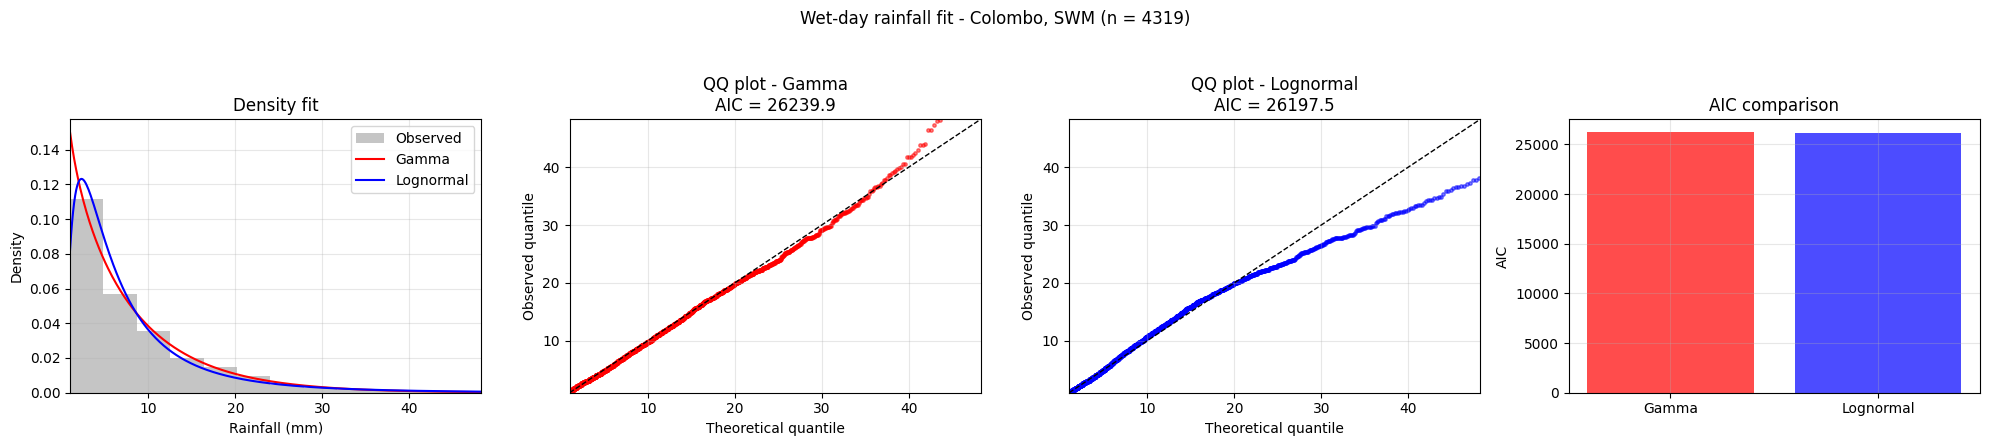

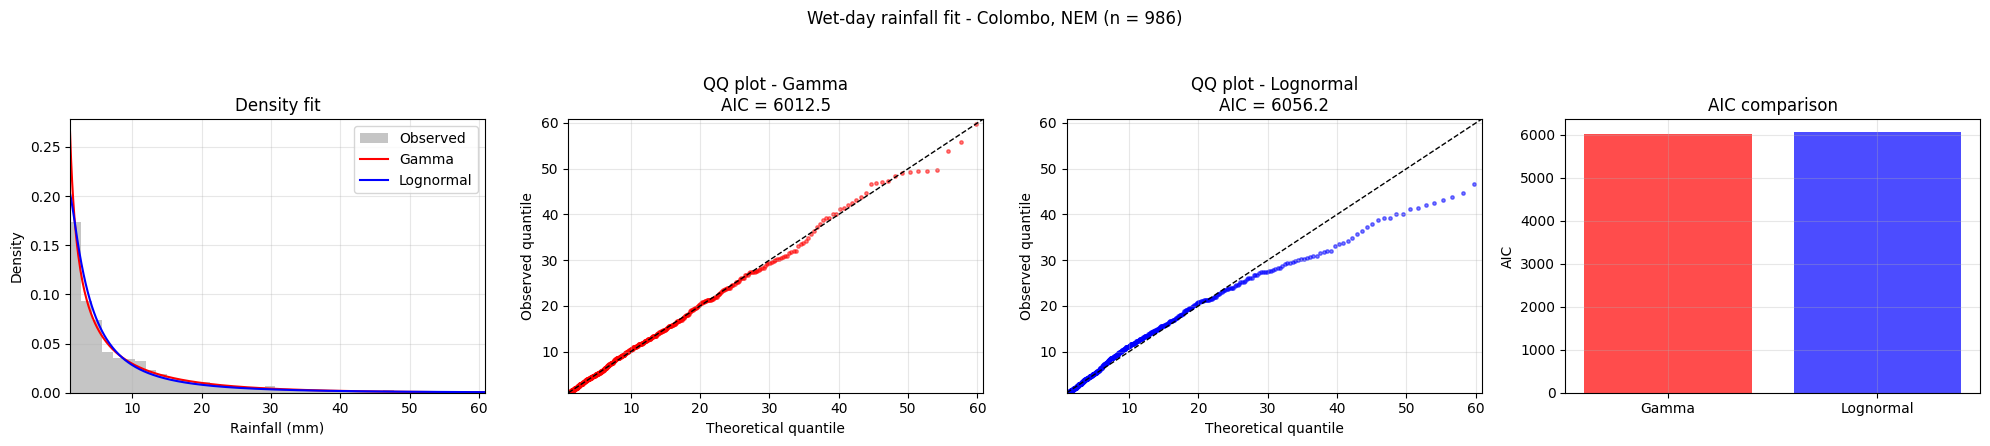

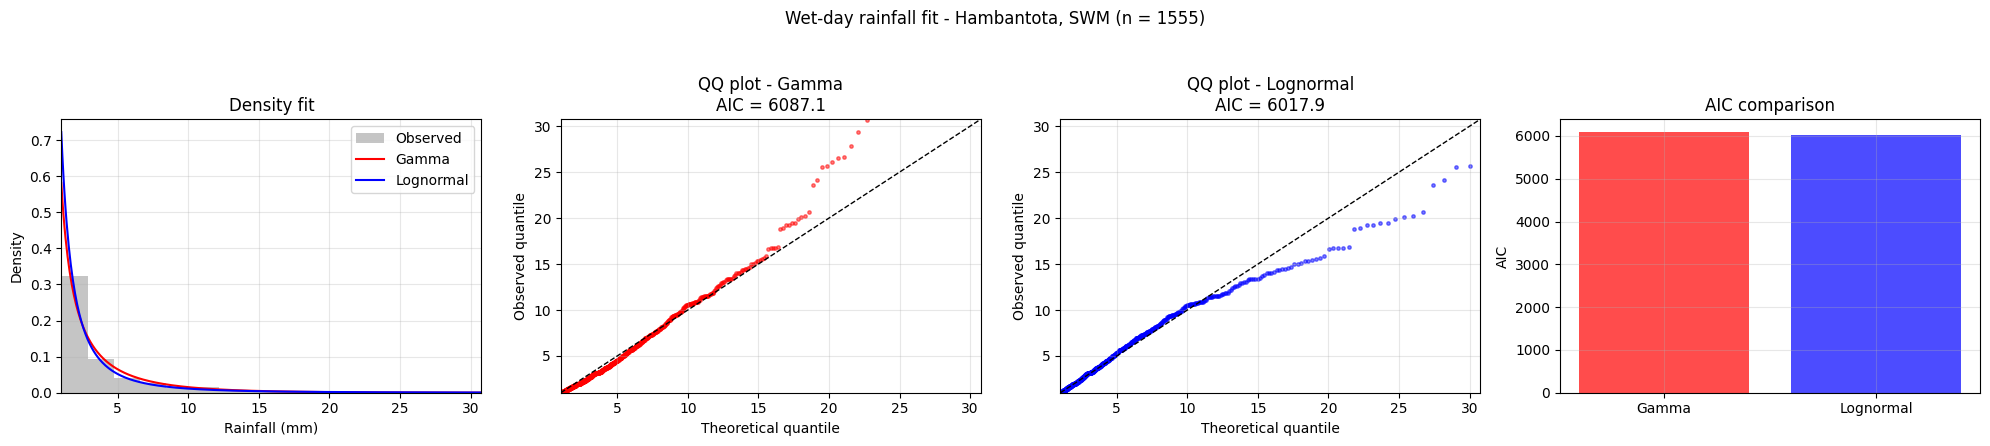

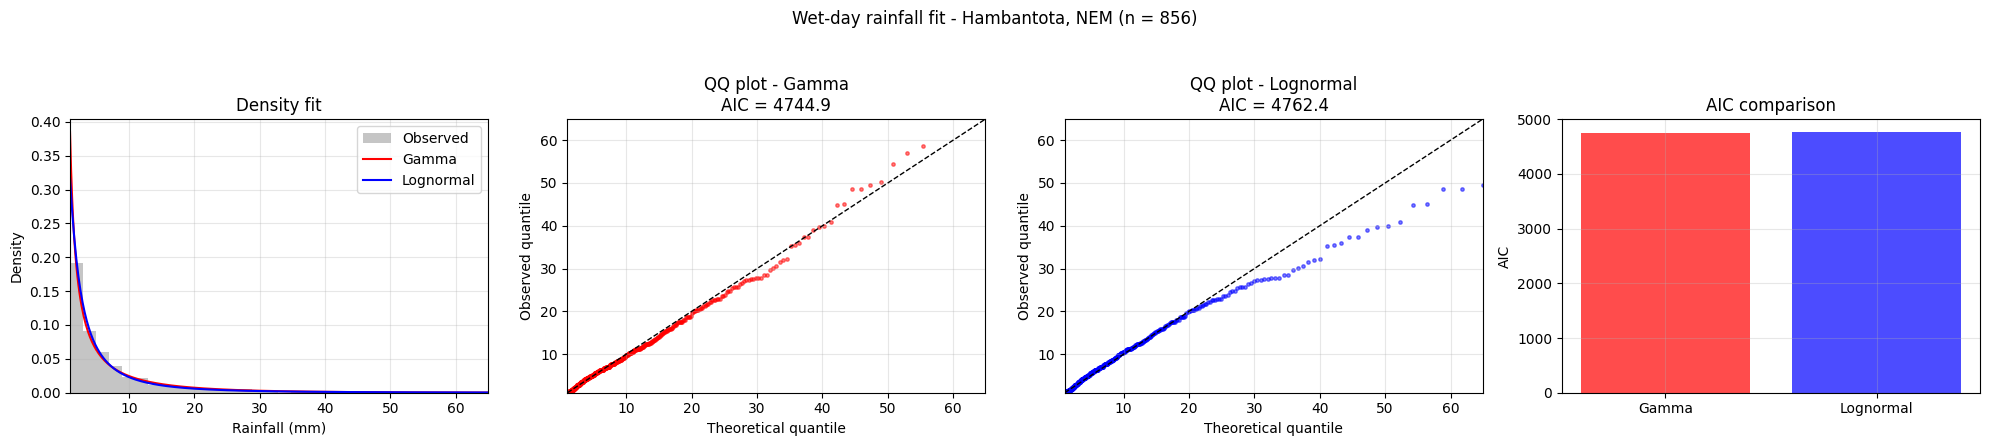

In [9]:
def plot_fit(key, x, fit):
    loc, season = key
    gam = stats.gamma(a=fit["gamma"][0], scale=fit["gamma"][1])
    logn = stats.lognorm(s=fit["lognormal"][0], scale=fit["lognormal"][1])
    aic_g = 4 - 2 * fit["gamma"][2]
    aic_l = 4 - 2 * fit["lognormal"][2]

    xmax = np.percentile(x, 99.5)
    grid = np.linspace(WET_DAY_THRESHOLD, xmax, 400)
    obs = np.sort(x)
    probs = (np.arange(1, len(x) + 1) - 0.5) / len(x)

    fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
    fig.suptitle(f"Wet-day rainfall fit - {loc}, {season} (n = {len(x)})")

    axes[0].hist(x, bins=60, density=True, alpha=0.45, color="grey", label="Observed")
    axes[0].plot(grid, gam.pdf(grid) / gam.sf(WET_DAY_THRESHOLD), "r-", label="Gamma")
    axes[0].plot(grid, logn.pdf(grid) / logn.sf(WET_DAY_THRESHOLD), "b-", label="Lognormal")
    axes[0].set_xlim(WET_DAY_THRESHOLD, xmax)
    axes[0].set_xlabel("Rainfall (mm)")
    axes[0].set_ylabel("Density")
    axes[0].set_title("Density fit")
    axes[0].legend()

    for ax, dist, name, color, aic in [
        (axes[1], gam, "Gamma", "red", aic_g),
        (axes[2], logn, "Lognormal", "blue", aic_l),
    ]:
        theo = dist.isf((1 - probs) * dist.sf(WET_DAY_THRESHOLD))
        ax.scatter(theo, obs, s=6, alpha=0.5, color=color)
        ax.plot([WET_DAY_THRESHOLD, xmax], [WET_DAY_THRESHOLD, xmax], "k--", lw=1)
        ax.set_xlim(WET_DAY_THRESHOLD, xmax)
        ax.set_ylim(WET_DAY_THRESHOLD, xmax)
        ax.set_xlabel("Theoretical quantile")
        ax.set_ylabel("Observed quantile")
        ax.set_title(f"QQ plot - {name}\nAIC = {aic:.1f}")

    axes[3].bar(["Gamma", "Lognormal"], [aic_g, aic_l], color=["red", "blue"], alpha=0.7)
    axes[3].set_ylabel("AIC")
    axes[3].set_title("AIC comparison")

    for ax in axes:
        ax.grid(alpha=0.3)

    plt.tight_layout(rect=[0, 0, 1, 0.94])
    plt.show()


for key, x in wet_amounts.items():
    plot_fit(key, x, fits[key])

## 4. Markov chain fitting

In [10]:
def count_transitions(wet_list):
    """2x2 counts, rows = today (0 dry, 1 wet), columns = tomorrow."""
    counts = np.zeros((2, 2), dtype=int)
    for w in wet_list:
        np.add.at(counts, (w[:-1], w[1:]), 1)
    return counts


chains = {}

for key, wet_list in wet_blocks.items():
    counts = count_transitions(wet_list)
    P = counts / counts.sum(axis=1, keepdims=True)
    pi_wet = P[0, 1] / (P[0, 1] + P[1, 0])
    chains[key] = {"counts": counts, "P": P, "pi_wet": pi_wet}

    print(f"\n{key[0]} - {key[1]}")
    print("  P(D|D) = %.4f   P(W|D) = %.4f" % (P[0, 0], P[0, 1]))
    print("  P(D|W) = %.4f   P(W|W) = %.4f" % (P[1, 0], P[1, 1]))
    print("  Stationary wet fraction: %.4f" % pi_wet)


Colombo - SWM
  P(D|D) = 0.3680   P(W|D) = 0.6320
  P(D|W) = 0.0396   P(W|W) = 0.9604
  Stationary wet fraction: 0.9410

Colombo - NEM
  P(D|D) = 0.8310   P(W|D) = 0.1690
  P(D|W) = 0.3018   P(W|W) = 0.6982
  Stationary wet fraction: 0.3589

Hambantota - SWM
  P(D|D) = 0.8113   P(W|D) = 0.1887
  P(D|W) = 0.3723   P(W|W) = 0.6277
  Stationary wet fraction: 0.3363

Hambantota - NEM
  P(D|D) = 0.8448   P(W|D) = 0.1552
  P(D|W) = 0.3455   P(W|W) = 0.6545
  Stationary wet fraction: 0.3099


In [11]:
# second-order chain: the row is yesterday's and today's state (DD, DW, WD, WW)
def count_transitions_2(wet_list):
    counts = np.zeros((4, 2), dtype=int)
    for w in wet_list:
        np.add.at(counts, (2 * w[:-2] + w[1:-1], w[2:]), 1)
    return counts


chains2 = {}

for key, wet_list in wet_blocks.items():
    counts = count_transitions_2(wet_list)
    assert (counts.sum(axis=1) > 0).all(), f"empty pair state for {key}"
    chains2[key] = counts / counts.sum(axis=1, keepdims=True)

    print(f"\n{key[0]} - {key[1]}  P(wet | previous two days)")
    for label, p in zip(["DD", "DW", "WD", "WW"], chains2[key][:, 1]):
        print(f"  {label}: {p:.3f}")


Colombo - SWM  P(wet | previous two days)
  DD: 0.551
  DW: 0.899
  WD: 0.686
  WW: 0.963

Colombo - NEM  P(wet | previous two days)
  DD: 0.152
  DW: 0.613
  WD: 0.251
  WW: 0.728

Hambantota - SWM  P(wet | previous two days)
  DD: 0.164
  DW: 0.563
  WD: 0.293
  WW: 0.663

Hambantota - NEM  P(wet | previous two days)
  DD: 0.127
  DW: 0.567
  WD: 0.286
  WW: 0.696


## 5. Simulation and verification

In [12]:
LONG_SPELL = 7


def simulate_first_order(P, n_days, n_sim, rng, start=None):
    """Simulate n_sim seasons at once. Returns an (n_sim, n_days) array, 1 = wet."""
    states = np.empty((n_sim, n_days), dtype=int)
    if start is None:
        pi_wet = P[0, 1] / (P[0, 1] + P[1, 0])
        states[:, 0] = rng.random(n_sim) < pi_wet
    else:
        states[:, 0] = start
    for t in range(1, n_days):
        states[:, t] = rng.random(n_sim) < P[states[:, t - 1], 1]
    return states


def simulate_second_order(P2, n_days, n_sim, rng, start_pairs):
    states = np.empty((n_sim, n_days), dtype=int)
    states[:, :2] = start_pairs
    for t in range(2, n_days):
        pair = 2 * states[:, t - 2] + states[:, t - 1]
        states[:, t] = rng.random(n_sim) < P2[pair, 1]
    return states


def spell_summary(states):
    """Longest dry spell of each season and the lengths of all dry spells."""
    n_sim, n_days = states.shape
    run = np.zeros(n_sim, dtype=int)
    longest = np.zeros(n_sim, dtype=int)
    lengths = []
    for t in range(n_days):
        dry = states[:, t] == 0
        previous = run
        run = np.where(dry, previous + 1, 0)
        lengths.append(previous[(~dry) & (previous > 0)])
        longest = np.maximum(longest, run)
    lengths.append(run[run > 0])
    return longest, np.concatenate(lengths)


def dry_spell_lengths(states):
    """Same thing for a single observed 0/1 sequence."""
    lengths, run = [], 0
    for s in states:
        if s == 0:
            run += 1
        elif run > 0:
            lengths.append(run)
            run = 0
    if run > 0:
        lengths.append(run)
    return lengths


# quick test on a known sequence
assert dry_spell_lengths([1, 0, 0, 0, 1, 0, 0, 1]) == [3, 2]
print("Dry-spell function test passed.")

Dry-spell function test passed.


In [13]:
rng_check = np.random.default_rng(SEED)

print("Check 1 and 2: long simulated runs against the exact results")
for key, c in chains.items():
    P = c["P"]
    sim = simulate_first_order(P, 1000, 2000, rng_check)
    _, lengths = spell_summary(sim)

    exact_spell = 1 / (1 - P[0, 0])
    print(f"  {key[0]:<10} {key[1]}: mean dry spell {lengths.mean():.3f} (exact {exact_spell:.3f}), "
          f"wet fraction {sim.mean():.4f} (exact {c['pi_wet']:.4f})")

    assert abs(lengths.mean() - exact_spell) / exact_spell < 0.03
    assert abs(sim.mean() - c["pi_wet"]) < 0.01

print("\nCheck 3: transition matrix rows sum to 1")
for key in chains:
    assert np.allclose(chains[key]["P"].sum(axis=1), 1.0)
    assert np.allclose(chains2[key].sum(axis=1), 1.0)
print("  passed for all first- and second-order matrices")

print("\nCheck 4: recover a known matrix from synthetic data")
P_true = np.array([[0.70, 0.30],
                   [0.40, 0.60]])
synthetic = simulate_first_order(P_true, 50_000, 1, rng_check)
est = count_transitions([synthetic[0]])
P_hat = est / est.sum(axis=1, keepdims=True)
print("  true:\n", P_true)
print("  estimated:\n", P_hat.round(4))
assert np.abs(P_hat - P_true).max() < 0.02
print("  max absolute error:", round(np.abs(P_hat - P_true).max(), 4))

Check 1 and 2: long simulated runs against the exact results
  Colombo    SWM: mean dry spell 1.580 (exact 1.582), wet fraction 0.9410 (exact 0.9410)
  Colombo    NEM: mean dry spell 5.881 (exact 5.917), wet fraction 0.3590 (exact 0.3589)
  Hambantota SWM: mean dry spell 5.287 (exact 5.300), wet fraction 0.3361 (exact 0.3363)
  Hambantota NEM: mean dry spell 6.396 (exact 6.444), wet fraction 0.3109 (exact 0.3099)

Check 3: transition matrix rows sum to 1
  passed for all first- and second-order matrices

Check 4: recover a known matrix from synthetic data
  true:
 [[0.7 0.3]
 [0.4 0.6]]
  estimated:
 [[0.7023 0.2977]
 [0.4005 0.5995]]
  max absolute error: 0.0023


## 5. Experiments and results

The experiment uses 10,000 seasons per random seed and 20 independent seeds for each location, monsoon and model configuration. Estimates are summarized across seeds using 95% t-confidence intervals. The historical sample contains 30 seasons per location and monsoon group; observed proportions use Wilson confidence intervals. The comparison includes first-order and second-order chains and observed seasonal statistics.


In [14]:
N_SIM = 10_000
N_SEEDS = 20


def mean_ci(values):
    """Mean and 95% t-interval across seeds."""
    values = np.asarray(values, dtype=float)
    half = stats.t.ppf(0.975, len(values) - 1) * values.std(ddof=1) / np.sqrt(len(values))
    return values.mean(), values.mean() - half, values.mean() + half


def monte_carlo(key, order, seed0):
    wet_list = wet_blocks[key]
    n_days = SEASON_LEN[key[1]]
    # each simulated season starts like a randomly chosen historical season
    starts = np.array([w[:2] for w in wet_list])

    per_seed = {"p_long": [], "mean_longest": [], "mean_spell": [], "wet_frac": []}
    pooled = []

    for s in range(N_SEEDS):
        rng = np.random.default_rng(seed0 + s)
        start = starts[rng.integers(0, len(starts), N_SIM)]

        if order == 1:
            sim = simulate_first_order(chains[key]["P"], n_days, N_SIM, rng, start[:, 0])
        else:
            sim = simulate_second_order(chains2[key], n_days, N_SIM, rng, start)

        longest, lengths = spell_summary(sim)
        per_seed["p_long"].append((longest >= LONG_SPELL).mean())
        per_seed["mean_longest"].append(longest.mean())
        per_seed["mean_spell"].append(lengths.mean())
        per_seed["wet_frac"].append(sim.mean())
        pooled.append(lengths)

    out = {name: mean_ci(v) for name, v in per_seed.items()}
    out["lengths"] = np.concatenate(pooled)
    return out


res1 = {key: monte_carlo(key, 1, SEED) for key in chains}

print(f"First-order chain: {N_SEEDS} seeds x {N_SIM:,} seasons, 95% CI across seeds")
for key, r in res1.items():
    print(f"\n{key[0]} - {key[1]}")
    print("  P(dry spell >= 7 days) = %.4f  [%.4f, %.4f]" % r["p_long"])
    print("  Mean longest dry spell = %.2f  [%.2f, %.2f] days" % r["mean_longest"])
    print("  Mean dry spell         = %.3f days (exact for an infinite chain: %.3f)"
          % (r["mean_spell"][0], 1 / (1 - chains[key]["P"][0, 0])))
    print("  Wet fraction           = %.4f  (stationary: %.4f)"
          % (r["wet_frac"][0], chains[key]["pi_wet"]))

First-order chain: 20 seeds x 10,000 seasons, 95% CI across seeds

Colombo - SWM
  P(dry spell >= 7 days) = 0.0139  [0.0135, 0.0143]
  Mean longest dry spell = 2.84  [2.83, 2.84] days
  Mean dry spell         = 1.578 days (exact for an infinite chain: 1.582)
  Wet fraction           = 0.9409  (stationary: 0.9410)

Colombo - NEM
  P(dry spell >= 7 days) = 0.9940  [0.9937, 0.9944]
  Mean longest dry spell = 16.02  [15.99, 16.04] days
  Mean dry spell         = 5.614 days (exact for an infinite chain: 5.917)
  Wet fraction           = 0.3644  (stationary: 0.3589)

Hambantota - SWM
  P(dry spell >= 7 days) = 0.9998  [0.9997, 0.9999]
  Mean longest dry spell = 17.43  [17.41, 17.45] days
  Mean dry spell         = 5.156 days (exact for an infinite chain: 5.300)
  Wet fraction           = 0.3396  (stationary: 0.3363)

Hambantota - NEM
  P(dry spell >= 7 days) = 0.9979  [0.9978, 0.9981]
  Mean longest dry spell = 17.47  [17.44, 17.50] days
  Mean dry spell         = 6.080 days (exact for an in

## 6. First-order vs second-order chain

In [15]:
def wilson(k, n, z=1.96):
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half


observed = {}
for key, wet_list in wet_blocks.items():
    spells = [dry_spell_lengths(w) for w in wet_list]
    longest = np.array([max(s, default=0) for s in spells])
    observed[key] = {
        "n_seasons": len(wet_list),
        "n_long": int((longest >= LONG_SPELL).sum()),
        "p_long": (longest >= LONG_SPELL).mean(),
        "mean_longest": longest.mean(),
        "lengths": np.array([x for s in spells for x in s]),
    }

res2 = {key: monte_carlo(key, 2, SEED + 1000) for key in chains}

rows = []
for key in chains:
    obs, r1, r2 = observed[key], res1[key], res2[key]
    lo, hi = wilson(obs["n_long"], obs["n_seasons"])
    rows.append({
        "Location": key[0],
        "Season": key[1],
        "Observed P(>=7d)": obs["p_long"],
        "Observed 95% CI": f"[{lo:.3f}, {hi:.3f}]",
        "1st order P(>=7d)": r1["p_long"][0],
        "2nd order P(>=7d)": r2["p_long"][0],
        "Observed mean longest": obs["mean_longest"],
        "1st order mean longest": r1["mean_longest"][0],
        "2nd order mean longest": r2["mean_longest"][0],
    })

comparison = pd.DataFrame(rows)
display(comparison.round(3))

for label, col in [("P(>=7d)", "P(>=7d)"), ("mean longest spell", "mean longest")]:
    err1 = (comparison[f"1st order {col}"] - comparison[f"Observed {col}"]).abs().mean()
    err2 = (comparison[f"2nd order {col}"] - comparison[f"Observed {col}"]).abs().mean()
    print(f"Mean absolute error in {label}: 1st order {err1:.3f}, 2nd order {err2:.3f}")

,Location,Season,Observed P(>=7d),Observed 95% CI,1st order P(>=7d),2nd order P(>=7d),Observed mean longest,1st order mean longest,2nd order mean longest
0,Colombo,SWM,0.033,"[0.006, 0.167]",0.014,0.031,2.933,2.835,2.996
1,Colombo,NEM,1.000,"[0.886, 1.000]",0.994,0.995,17.033,16.017,17.142
2,Hambantota,SWM,1.000,"[0.886, 1.000]",1.000,1.000,22.667,17.429,19.281
3,Hambantota,NEM,1.000,"[0.886, 1.000]",0.998,0.999,22.067,17.469,19.821


Mean absolute error in P(>=7d): 1st order 0.007, 2nd order 0.002
Mean absolute error in mean longest spell: 1st order 2.737, 2nd order 1.451


In [16]:
def draw_wet_amounts(n, shape, scale, rng):
    """Draw from the gamma fit truncated below at the wet-day threshold."""
    dist = stats.gamma(a=shape, scale=scale)
    u = 1 - rng.random(n)
    return dist.isf(u * dist.sf(WET_DAY_THRESHOLD))


rng_amt = np.random.default_rng(SEED + 2000)
rows = []

for key in chains:
    shape, scale, _ = fits[key]["gamma"]
    sim = simulate_first_order(chains[key]["P"], SEASON_LEN[key[1]], 2000, rng_amt)

    rain = np.zeros(sim.shape)
    rain[sim == 1] = draw_wet_amounts(int(sim.sum()), shape, scale, rng_amt)

    obs_totals = [r[w == 1].sum() for r, w in zip(rain_blocks[key], wet_blocks[key])]
    rows.append({
        "Location": key[0],
        "Season": key[1],
        "Observed mean wet day (mm)": wet_amounts[key].mean(),
        "Simulated mean wet day (mm)": rain[sim == 1].mean(),
        "Observed wet-day total (mm)": np.mean(obs_totals),
        "Simulated wet-day total (mm)": rain.sum(axis=1).mean(),
    })

display(pd.DataFrame(rows).round(1))

,Location,Season,Observed mean wet day (mm),Simulated mean wet day (mm),Observed wet-day total (mm),Simulated wet-day total (mm)
0,Colombo,SWM,8.7,8.7,1249.9,1248.3
1,Colombo,NEM,9.3,9.2,304.3,295.9
2,Hambantota,SWM,3.9,3.9,204.3,202.0
3,Hambantota,NEM,7.6,7.6,216.8,215.9


## 7. Figures

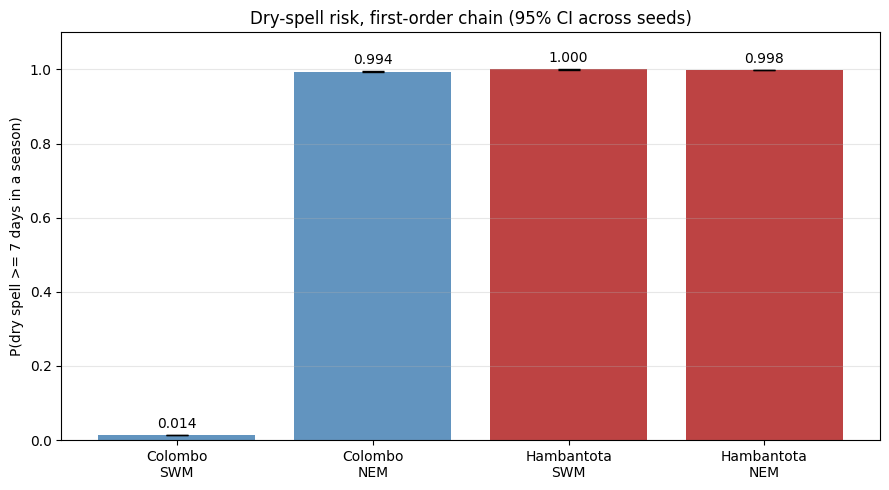

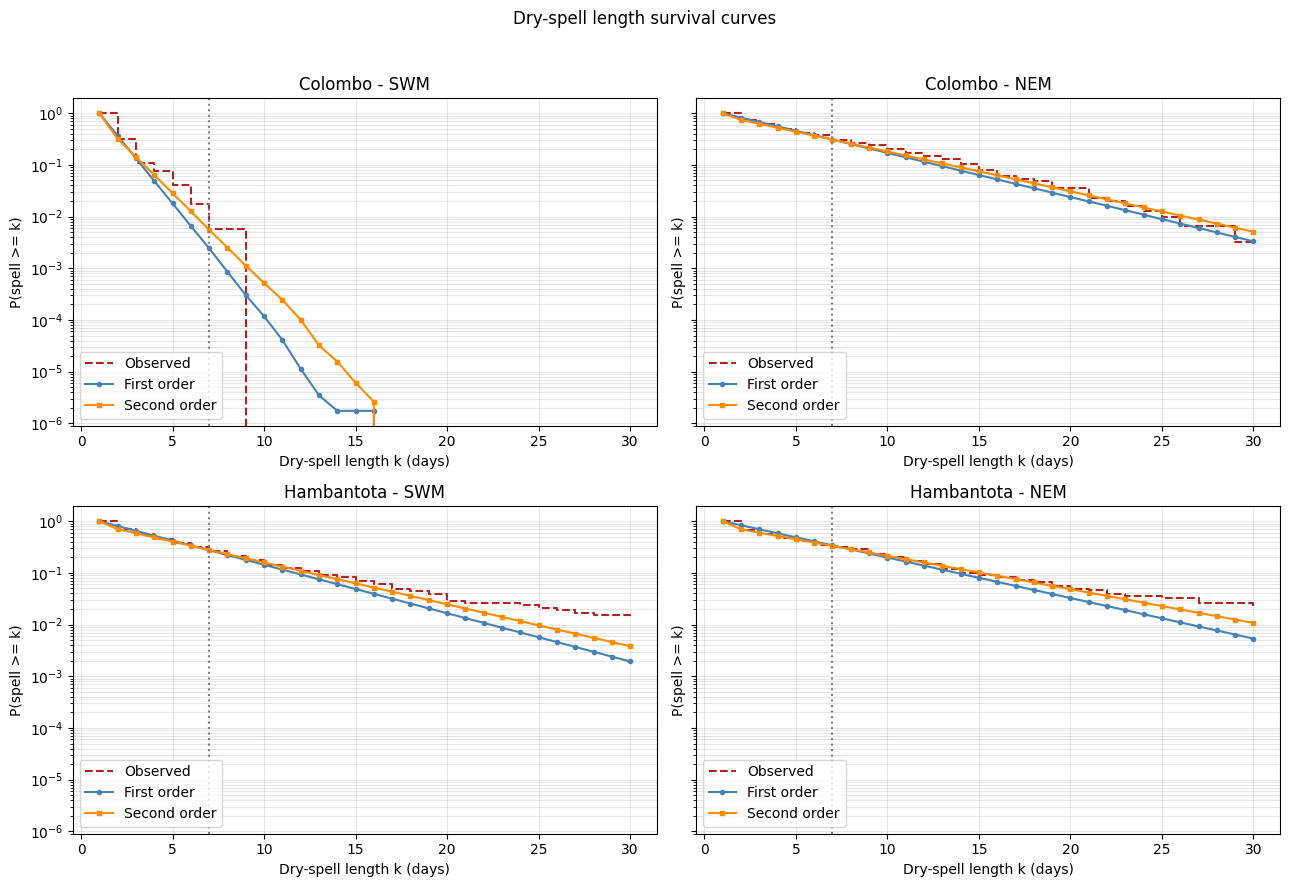

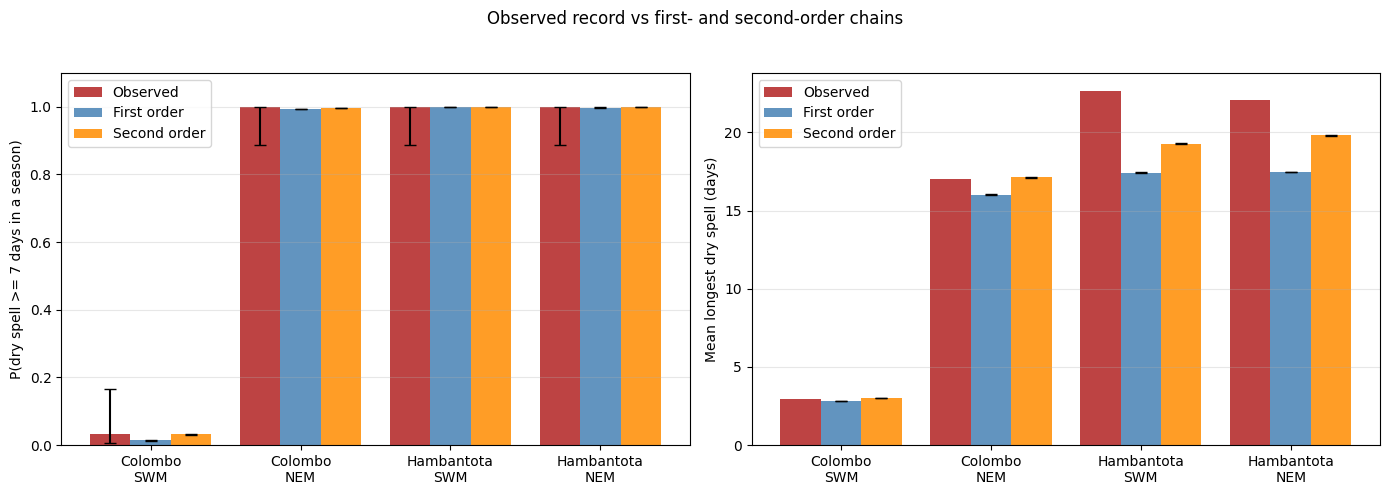

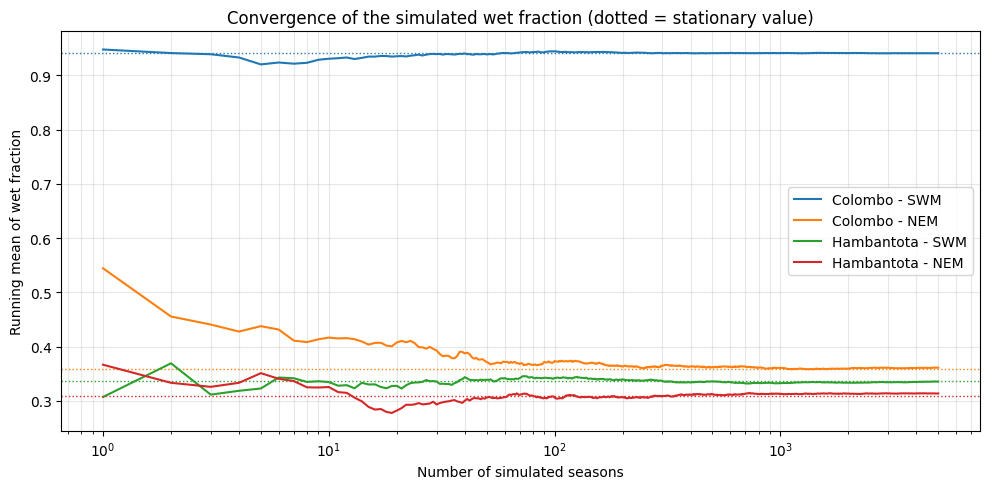

In [17]:
keys = list(chains)
palette = {"Colombo": "steelblue", "Hambantota": "firebrick"}

# P(dry spell >= 7 days), first-order chain
fig, ax = plt.subplots(figsize=(9, 5))
vals = [res1[k]["p_long"][0] for k in keys]
errs = [res1[k]["p_long"][0] - res1[k]["p_long"][1] for k in keys]
bars = ax.bar([f"{l}\n{s}" for l, s in keys], vals, yerr=errs, capsize=8,
              color=[palette[l] for l, _ in keys], alpha=0.85)
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.02, f"{v:.3f}", ha="center")
ax.set_ylim(0, 1.1)
ax.set_ylabel("P(dry spell >= 7 days in a season)")
ax.set_title("Dry-spell risk, first-order chain (95% CI across seeds)")
ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()

# survival curves of dry-spell length
ks = np.arange(1, 31)
survival = lambda lengths: np.array([(lengths >= k).mean() for k in ks])

fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharey=True)
for ax, key in zip(axes.flat, keys):
    ax.step(ks, survival(observed[key]["lengths"]), where="post", ls="--",
            color="firebrick", label="Observed")
    ax.plot(ks, survival(res1[key]["lengths"]), marker="o", ms=3, color="steelblue",
            label="First order")
    ax.plot(ks, survival(res2[key]["lengths"]), marker="s", ms=3, color="darkorange",
            label="Second order")
    ax.axvline(7, color="grey", ls=":")
    ax.set_yscale("log")
    ax.set_title(f"{key[0]} - {key[1]}")
    ax.set_xlabel("Dry-spell length k (days)")
    ax.set_ylabel("P(spell >= k)")
    ax.grid(alpha=0.3, which="both")
    ax.legend(loc="lower left")
fig.suptitle("Dry-spell length survival curves")
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

# observed vs first order vs second order
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
x = np.arange(len(keys))
w = 0.27

def yerr(means, los, his):
    return np.array([np.array(means) - np.array(los), np.array(his) - np.array(means)])

obs_ci = [wilson(observed[k]["n_long"], observed[k]["n_seasons"]) for k in keys]
obs_p = [observed[k]["p_long"] for k in keys]
axes[0].bar(x - w, obs_p, w, label="Observed", color="firebrick", alpha=0.85,
            yerr=yerr(obs_p, [c[0] for c in obs_ci], [c[1] for c in obs_ci]), capsize=4)
for shift, res, name, color in [(0, res1, "First order", "steelblue"),
                                (w, res2, "Second order", "darkorange")]:
    m = [res[k]["p_long"][0] for k in keys]
    axes[0].bar(x + shift, m, w, label=name, color=color, alpha=0.85,
                yerr=yerr(m, [res[k]["p_long"][1] for k in keys],
                          [res[k]["p_long"][2] for k in keys]), capsize=4)
axes[0].set_ylabel("P(dry spell >= 7 days in a season)")
axes[0].set_ylim(0, 1.1)

axes[1].bar(x - w, [observed[k]["mean_longest"] for k in keys], w,
            label="Observed", color="firebrick", alpha=0.85)
for shift, res, name, color in [(0, res1, "First order", "steelblue"),
                                (w, res2, "Second order", "darkorange")]:
    m = [res[k]["mean_longest"][0] for k in keys]
    axes[1].bar(x + shift, m, w, label=name, color=color, alpha=0.85,
                yerr=yerr(m, [res[k]["mean_longest"][1] for k in keys],
                          [res[k]["mean_longest"][2] for k in keys]), capsize=4)
axes[1].set_ylabel("Mean longest dry spell (days)")

for ax in axes:
    ax.set_xticks(x)
    ax.set_xticklabels([f"{l}\n{s}" for l, s in keys])
    ax.grid(alpha=0.3, axis="y")
    ax.legend()
fig.suptitle("Observed record vs first- and second-order chains")
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

# law of large numbers: running mean of the simulated wet fraction
rng_lln = np.random.default_rng(SEED + 3000)
fig, ax = plt.subplots(figsize=(10, 5))
for key in keys:
    sim = simulate_first_order(chains[key]["P"], SEASON_LEN[key[1]], 5000, rng_lln)
    running = np.cumsum(sim.mean(axis=1)) / np.arange(1, 5001)
    line, = ax.plot(np.arange(1, 5001), running, label=f"{key[0]} - {key[1]}")
    ax.axhline(chains[key]["pi_wet"], color=line.get_color(), ls=":", lw=1)
ax.set_xscale("log")
ax.set_xlabel("Number of simulated seasons")
ax.set_ylabel("Running mean of wet fraction")
ax.set_title("Convergence of the simulated wet fraction (dotted = stationary value)")
ax.grid(alpha=0.3, which="both")
ax.legend()
plt.tight_layout()
plt.show()

## 8. Summary table

In [18]:
summary = pd.DataFrame({
    "Location": [k[0] for k in keys],
    "Season": [k[1] for k in keys],
    "P(D|D)": [chains[k]["P"][0, 0] for k in keys],
    "Stationary wet %": [chains[k]["pi_wet"] * 100 for k in keys],
    "Observed P(>=7d)": [observed[k]["p_long"] for k in keys],
    "1st order P(>=7d)": [res1[k]["p_long"][0] for k in keys],
    "1st order 95% CI": ["[%.3f, %.3f]" % res1[k]["p_long"][1:] for k in keys],
    "2nd order P(>=7d)": [res2[k]["p_long"][0] for k in keys],
    "2nd order 95% CI": ["[%.3f, %.3f]" % res2[k]["p_long"][1:] for k in keys],
    "Observed mean longest": [observed[k]["mean_longest"] for k in keys],
    "1st order mean longest": [res1[k]["mean_longest"][0] for k in keys],
    "2nd order mean longest": [res2[k]["mean_longest"][0] for k in keys],
})

display(summary.round(3))

,Location,Season,P(D|D),Stationary wet %,Observed P(>=7d),1st order P(>=7d),1st order 95% CI,2nd order P(>=7d),2nd order 95% CI,Observed mean longest,1st order mean longest,2nd order mean longest
0,Colombo,SWM,0.368,94.101,0.033,0.014,"[0.013, 0.014]",0.031,"[0.031, 0.032]",2.933,2.835,2.996
1,Colombo,NEM,0.831,35.895,1.000,0.994,"[0.994, 0.994]",0.995,"[0.995, 0.996]",17.033,16.017,17.142
2,Hambantota,SWM,0.811,33.633,1.000,1.000,"[1.000, 1.000]",1.000,"[1.000, 1.000]",22.667,17.429,19.281
3,Hambantota,NEM,0.845,30.994,1.000,0.998,"[0.998, 0.998]",0.999,"[0.998, 0.999]",22.067,17.469,19.821


In [19]:

# Extract exact values needed by the browser demo

for key in chains:

    location, season = key
    starts = np.array([w[:2] for w in wet_blocks[key]])

    print("\n", location, "-", season)

    print("Full-precision first-order matrix:")
    print(repr(chains[key]["P"]))

    print("Historical first-day wet proportion:")
    print(float(starts[:, 0].mean()))

    print("Full-precision second-order matrix:")
    print(repr(chains2[key]))

    print("Historical first-two-day state frequencies:")
    unique, counts = np.unique(
        starts[:, 0] * 2 + starts[:, 1],
        return_counts=True
    )

    print(dict(zip(unique.tolist(), (counts / len(starts)).tolist())))



 Colombo - SWM
Full-precision first-order matrix:
array([[0.36802974, 0.63197026],
       [0.0396178 , 0.9603822 ]])
Historical first-day wet proportion:
0.9333333333333333
Full-precision second-order matrix:
array([[0.44897959, 0.55102041],
       [0.10119048, 0.89880952],
       [0.31360947, 0.68639053],
       [0.03711844, 0.96288156]])
Historical first-two-day state frequencies:
{0: 0.06666666666666667, 2: 0.03333333333333333, 3: 0.9}

 Colombo - NEM
Full-precision first-order matrix:
array([[0.83098592, 0.16901408],
       [0.30184805, 0.69815195]])
Historical first-day wet proportion:
0.6
Full-precision second-order matrix:
array([[0.84768683, 0.15231317],
       [0.38732394, 0.61267606],
       [0.74912892, 0.25087108],
       [0.27232143, 0.72767857]])
Historical first-two-day state frequencies:
{0: 0.3333333333333333, 1: 0.06666666666666667, 2: 0.03333333333333333, 3: 0.5666666666666667}

 Hambantota - SWM
Full-precision first-order matrix:
array([[0.81132075, 0.18867925],
  

## 6. Discussion and limitations

The chains estimate wet/dry persistence within the selected historical period and assume stationary transition behaviour within each location and season. The second-order chain uses only two days of history. The historical sample is limited to 30 seasons per group, so observed risk estimates have uncertainty. ERA5 is reanalysis, not direct station data at the exact coordinates; grid-scale rainfall may differ from local measurements. Simulated NEM seasons are standardized to 90 days, while the historical NEM may contain 90 or 91 days. The rainfall amount model is fitted only to wet days and omits other meteorological drivers. Results depend on the data source, threshold, season definitions, fitted parameters and model structure. They are not forecasts or direct estimates of agricultural impacts.

The second-order chain can represent persistence patterns missed by the first-order model, but improved metrics in this experiment do not establish universal superiority. Further study could evaluate other thresholds, longer-memory models, additional locations, station observations, time-varying parameters and independent validation periods.



## 7. References

1. Open-Meteo, “Historical Weather API documentation.” https://open-meteo.com/en/docs/historical-weather-api (accessed 26 November 2026).
2. J. R. Norris, *Markov Chains*. Cambridge University Press, 1997.
3. D. S. Wilks, *Statistical Methods in the Atmospheric Sciences*, 3rd ed. Academic Press, 2011.

The precipitation data are retrieved from the Open-Meteo Historical Weather API. The historical values are reanalysis estimates rather than station observations.
